# Assignment 1 — EDA & Baseline: Forecasting Sticker Sales

**Competition:** [Playground Series S5E1 – Forecasting Sticker Sales](https://www.kaggle.com/competitions/playground-series-s5e1)

## 1. Problem definition

- **Task:** forecast how many stickers are sold per day, in each country, store and product, for 2017–2019.
- **Data:** daily sales for 2010–2016. Each row is one day × country × store × product.
- **Target variable:** `num_sold`, the number of stickers sold that day.
- **Evaluation metric:** **MAPE** (mean absolute percentage error), the average of `|real − predicted| / real`. Lower is better.
- **Why MAPE matters for the design:** the error is relative, so missing a small value (5 vs. 15 = 200%) costs far more than missing a large one (1000 vs. 1010 = 1%). Low-volume series will dominate the score.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_data, preprocess, FEATURES
from src.models import naive_baseline, train_model, predict
from src.utils import mape, save_submission

train, test = load_data("data")

## 2. Data overview

In [2]:
print("train:", train.shape, "  test:", test.shape)
print("train dates:", train.date.min().date(), "→", train.date.max().date())
print("test dates: ", test.date.min().date(), "→", test.date.max().date())
train.head()

train: (230130, 6)   test: (98550, 5)
train dates: 2010-01-01 → 2016-12-31
test dates:  2017-01-01 → 2019-12-31


,id,date,country,store,product,num_sold
0,0,2010-01-01,Canada,Discount Stickers,Holographic Goose,NaN
1,1,2010-01-01,Canada,Discount Stickers,Kaggle,973.0
2,2,2010-01-01,Canada,Discount Stickers,Kaggle Tiers,906.0
3,3,2010-01-01,Canada,Discount Stickers,Kerneler,423.0
4,4,2010-01-01,Canada,Discount Stickers,Kerneler Dark Mode,491.0


In [3]:
train.dtypes

id                   int64
date        datetime64[us]
country                str
store                  str
product                str
num_sold           float64
dtype: object

In [4]:
train.describe()

,id,date,num_sold
count,230130.000000,230130,221259.000000
mean,115064.500000,2013-07-01 23:59:59.999999,752.527382
min,0.000000,2010-01-01 00:00:00,5.000000
25%,57532.250000,2011-10-02 00:00:00,219.000000
50%,115064.500000,2013-07-02 00:00:00,605.000000
75%,172596.750000,2015-04-02 00:00:00,1114.000000
max,230129.000000,2016-12-31 00:00:00,5939.000000
std,66432.953062,NaN,690.165445


In [5]:
train[["country", "store", "product"]].describe()

,country,store,product
count,230130,230130,230130
unique,6,3,5
top,Canada,Discount Stickers,Holographic Goose
freq,38355,76710,46026


In [6]:
print("Missing values per column:")
print(train.isna().sum(), "\n")
print("Missing num_sold by country and product:")
train[train.num_sold.isna()].groupby(["country", "product"]).size()

Missing values per column:
id             0
date           0
country        0
store          0
product        0
num_sold    8871
dtype: int64 

Missing num_sold by country and product:


country  product           
Canada   Holographic Goose     4245
         Kerneler                 1
Kenya    Holographic Goose     4561
         Kerneler                63
         Kerneler Dark Mode       1
dtype: int64

In [7]:
print("Fully duplicated rows:", train.duplicated().sum())
print("Duplicated (date, country, store, product) keys:",
      train.duplicated(subset=["date", "country", "store", "product"]).sum())
print("Number of series:", train.groupby(["country", "store", "product"]).ngroups)

Fully duplicated rows: 0
Duplicated (date, country, store, product) keys: 0
Number of series: 90


**Interpretation**

- The training set has **230,130 rows** and the test set **98,550 rows**. Test dates start the day after training ends, so this is pure forecasting into the future.
- There are **90 series** (6 countries × 3 stores × 5 products), stacked into one table.
- `country`, `store` and `product` are text labels; `date` is a date; `num_sold` is the only numeric value we predict.
- **8,871 values of `num_sold` are missing**, only in Canada and Kenya, and almost all for Holographic Goose. These are the lowest-selling combinations, so the missing values most likely are sales too small to be recorded. They are **not missing at random**.
- **No duplicate rows or duplicate keys**, so every (date, country, store, product) appears once. 

## 3. Exploratory data analysis

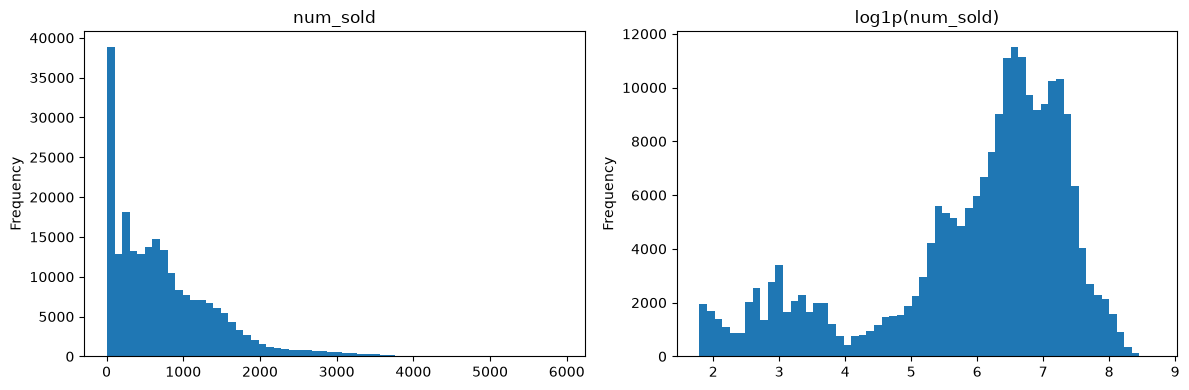

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
train.num_sold.plot(kind="hist", bins=60, ax=ax[0], title="num_sold")
np.log1p(train.num_sold).plot(kind="hist", bins=60, ax=ax[1], title="log1p(num_sold)")
plt.tight_layout(); plt.show()

**Interpretation:** The raw target is strongly right-skewed: most days sell a few hundred stickers, a long tail reaches into the thousands. On a log scale the distribution is much more compact. This, together with the relative MAPE metric, is the reason the model is trained on `log1p(num_sold)` (section 5). The log scale reveals two groups: low-volume (Kenya and similar) and normal.

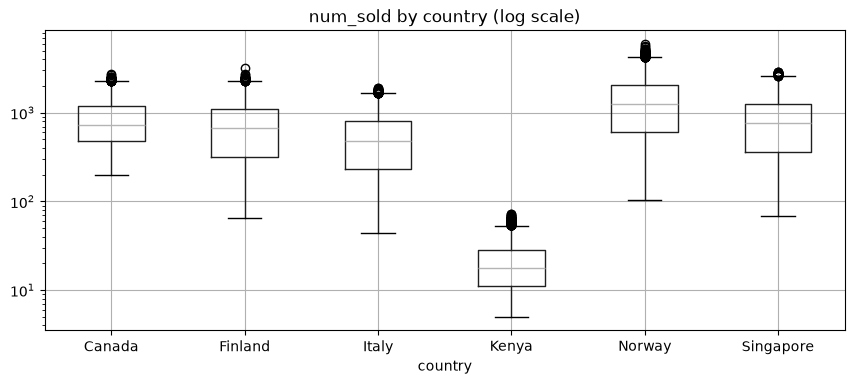

In [9]:
order = train.groupby("country").num_sold.median().sort_values().index
ax = train.boxplot(column="num_sold", by="country", positions=range(len(order)), figsize=(10, 4))
ax.set_yscale("log"); ax.set_title("num_sold by country (log scale)"); plt.suptitle(""); plt.show()

**Interpretation (outliers):** sales levels differ by orders of magnitude between countries, so a single global outlier rule would flag all of Norway or all of Kenya. Within each country, the points above the whiskers are rare high days; the time plot below shows they are short spikes at fixed times of year (likely holidays), i.e. real behaviour, not errors. They are kept.

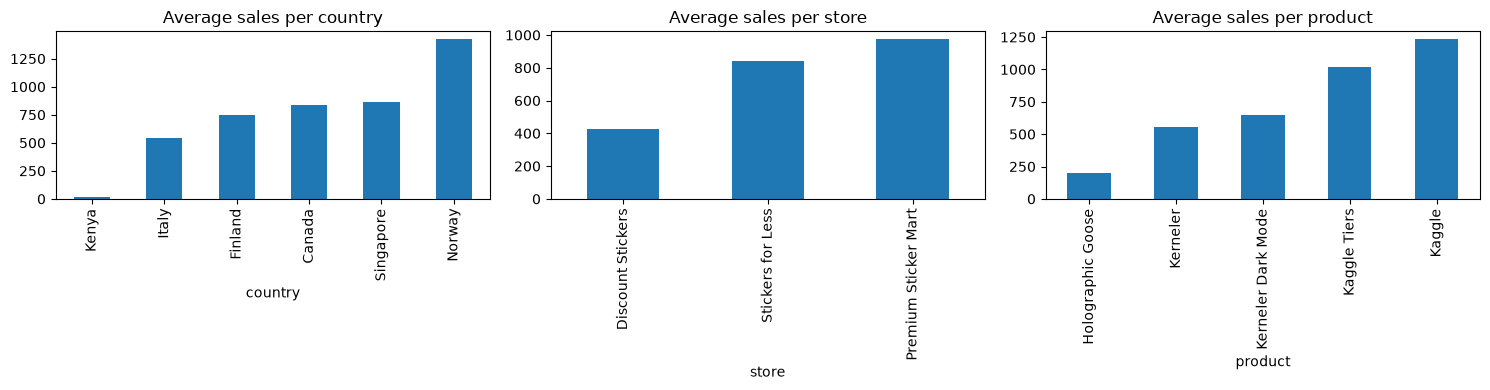

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["country", "store", "product"]):
    train.groupby(c).num_sold.mean().sort_values().plot(kind="bar", ax=a, title=f"Average sales per {c}")
plt.tight_layout(); plt.show()

**Interpretation (relationships with the target):**
- **Country is the strongest factor:** ~20 sales/day in Kenya vs. ~1,423 in Norway, about 70× more.
- **Store:** Premium Sticker Mart (~974) sells about 2.3× Discount Stickers (~428).
- **Product:** Kaggle (~1,232) sells about 6× Holographic Goose (~197).
- Because the differences look like constant ratios between groups, sales behave roughly like *base × country × store × product*. A log target turns these products into sums, which tree models split on easily.

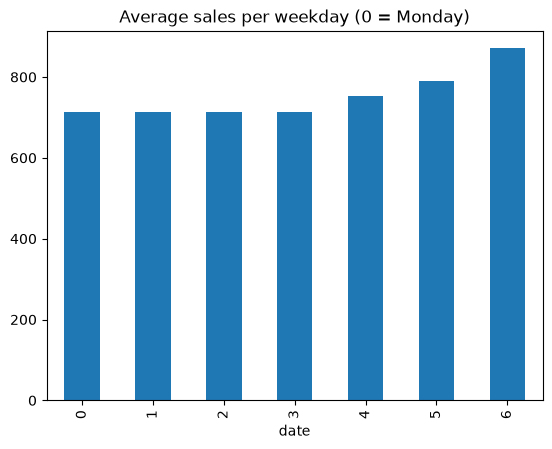

In [11]:
train.groupby(train.date.dt.day_of_week).num_sold.mean().plot(kind="bar", title="Average sales per weekday (0 = Monday)");

**Interpretation:** Monday–Thursday are flat at ~713. Friday (~752), Saturday (~791) and Sunday (~871) step up, Sunday about 22% above a weekday. The effect is smaller than country or product but clear and regular, so weekday is a feature.

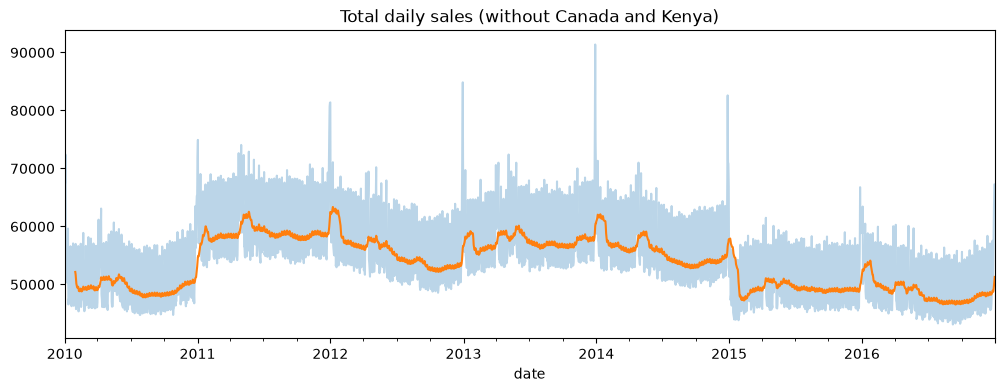

In [12]:
clean = train[~train.country.isin(["Canada", "Kenya"])]   # countries with missing values excluded so gaps don't look like dips
daily = clean.groupby("date").num_sold.sum()
ax = daily.plot(alpha=.3, figsize=(12, 4), title="Total daily sales (without Canada and Kenya)")
daily.rolling(30).mean().plot(ax=ax); plt.show()

**Interpretation:**
- There is no smooth long-term growth. The level jumps at year boundaries (up in 2011, down in 2015), which means something is set once per year.
- A yearly seasonal pattern repeats, and sharp one-day spikes appear at the same times each year (likely holidays).
- The thick band is the weekly cycle from the weekday plot.

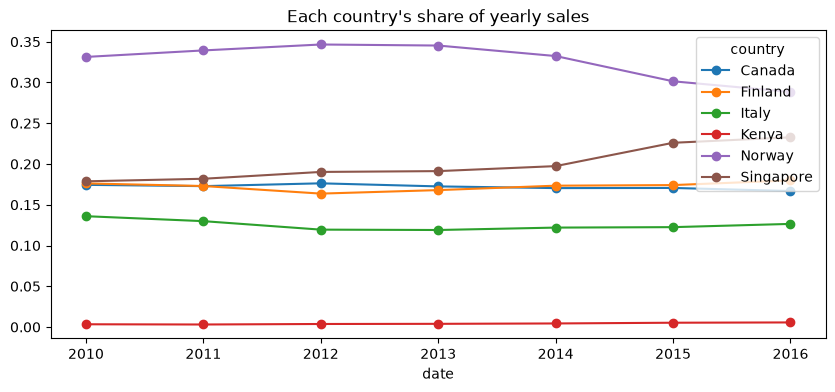

In [13]:
yearly = train.groupby([train.date.dt.year, "country"]).num_sold.sum().unstack()
yearly.div(yearly.sum(axis=1), axis=0).plot(marker="o", figsize=(10, 4), title="Each country's share of yearly sales");

**Interpretation:** country shares change from year to year: Norway falls after 2014, Singapore rises. The country name alone cannot explain this, because "Norway" is the same label every year. Something per country and per year drives sales. This is the main limitation of a model that sees only categories and dates (see Conclusion).

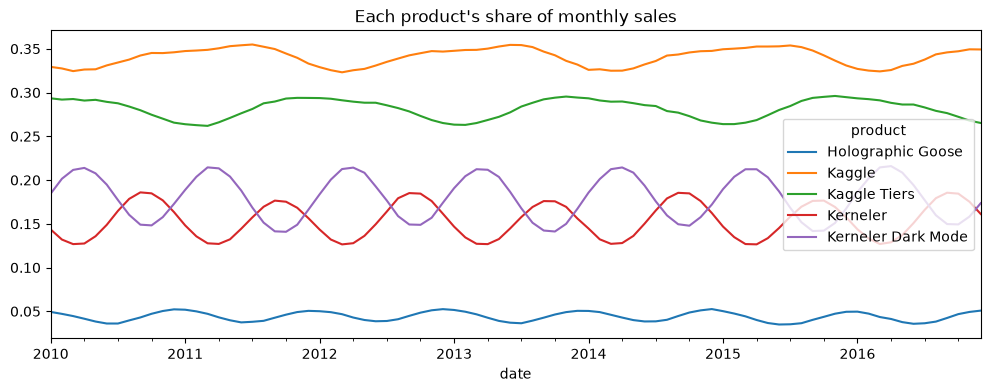

In [14]:
monthly = train.groupby([pd.Grouper(key="date", freq="ME"), "product"]).num_sold.sum().unstack()
monthly.div(monthly.sum(axis=1), axis=0).plot(figsize=(12, 4), title="Each product's share of monthly sales");

**Interpretation:** each product's share follows a smooth, repeating wave (for example Kerneler and Kerneler Dark Mode move in opposite phase). Because the waves depend only on the date, calendar features (`dayofyear`, `month`) let the model learn them.

## 4. Preprocessing

I dropped the 8,871 rows with missing num_sold. Filling them with zeros would teach the model fake zeros and cause 100% errors on the real small values in the test set, and dropping them only costs about 4% of the data. The model can’t read a raw date, so I split date into year, month, weekday and dayofyear, which carry the weekly and yearly patterns from the EDA. country, store and product are labels, not quantities, so I marked them as categories; LightGBM can split on categories directly, so one-hot encoding isn’t needed. I didn’t scale anything, because tree models split on thresholds and the scale of a feature doesn’t matter to them. The target is trained on log1p(num_sold) (section 5) to make errors relative, like MAPE, and to compress the skewed distribution. I kept the outliers, since the spikes are real repeating events like holidays, not data errors. The functions are in src/data.py.

In [15]:
train = preprocess(train.dropna(subset=["num_sold"]))
test = preprocess(test)

print("train:", train.shape, "  test:", test.shape)
print("features:", FEATURES)
train[FEATURES + ["num_sold"]].head()

train: (221259, 10)   test: (98550, 9)
features: ['country', 'store', 'product', 'year', 'month', 'weekday', 'dayofyear']


,country,store,product,year,month,weekday,dayofyear,num_sold
1,Canada,Discount Stickers,Kaggle,2010,1,4,1,973.0
2,Canada,Discount Stickers,Kaggle Tiers,2010,1,4,1,906.0
3,Canada,Discount Stickers,Kerneler,2010,1,4,1,423.0
4,Canada,Discount Stickers,Kerneler Dark Mode,2010,1,4,1,491.0
5,Canada,Stickers for Less,Holographic Goose,2010,1,4,1,300.0


## 5. Baseline model

**Validation:** the test set lies entirely in the future, so the validation split is by time, not random: train on 2010–2015, validate on 2016. A random split would let the model see the days around each hidden day and overstate accuracy.

Two baselines are compared:
1. **Naive:** predict each 2016 day as the 2015 average of the same series and weekday.
2. **LightGBM:** gradient-boosted decision trees on the 7 features, trained on `log1p(num_sold)`.

In [16]:
learn = train[train.year < 2016]
exam = train[train.year == 2016]

naive_guess = naive_baseline(learn, exam)
print(f"Naive baseline  2016 MAPE: {mape(exam.num_sold, naive_guess):.2f}%")

model = train_model(learn)
lgb_guess = predict(model, exam)
print(f"LightGBM (log)  2016 MAPE: {mape(exam.num_sold, lgb_guess):.2f}%")

model_raw = train_model(learn, log_target=False)
print(f"LightGBM (raw)  2016 MAPE: {mape(exam.num_sold, predict(model_raw, exam)):.2f}%")

Naive baseline  2016 MAPE: 10.35%
LightGBM (log)  2016 MAPE: 6.94%
LightGBM (raw)  2016 MAPE: 11.50%


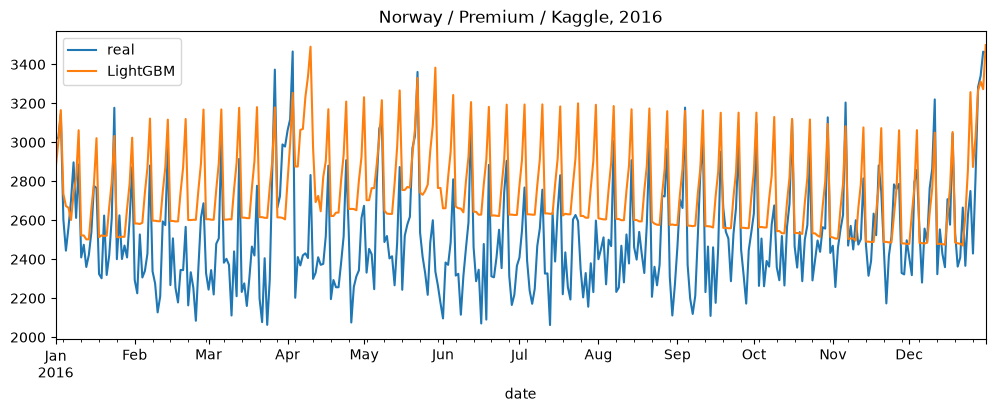

In [17]:
s = (exam.country == "Norway") & (exam.store == "Premium Sticker Mart") & (exam["product"] == "Kaggle")
pd.DataFrame({"real": exam.loc[s, "num_sold"].values, "LightGBM": lgb_guess[s.values]},
             index=exam.loc[s, "date"]).plot(figsize=(12, 4), title="Norway / Premium / Kaggle, 2016");

**Interpretation:**
- LightGBM reaches 6.94% MAPE on 2016. The naive baseline scores 10.35%, so LightGBM improves on it by 3.41 points.
- Without the log target, LightGBM scores 11.50%, which is even worse than the naive baseline. Training on the log target matters more than the model itself, because it makes errors relative, like MAPE.
- In the plot, the model follows the weekly ups and downs. It usually sits above the real line, so it over-predicts this series, with changing accuracy.

## 6. Kaggle submission

The competition is closed, so a late submission is used. The final model is retrained on all of 2010–2016, because 2016 is the closest year to the forecast period and was held out only for validation.

In [18]:
final = train_model(train)
submission = save_submission(test, predict(final, test))
print(submission.shape)
submission.head()

(98550, 2)


,id,num_sold
0,230130,101.699421
1,230131,823.143068
2,230132,749.097559
3,230133,376.960921
4,230134,453.683293


The Kaggle score (12.55% public, 16.36% private) is worse than validation (6.94%) because the test is 3 years ahead. The model can’t extrapolate yearly level shifts, which GDP per capita could fix in Assignment 2.

![Kaggle late submission score](submissions/kaggle_score.png)

## 7. Conclusion

**Key findings**
- Sales follow a roughly multiplicative structure: country (≈70× range), product, store and weekday each scale sales.
- Missing targets are tiny unrecorded sales in Canada and Kenya, not random gaps.
- Sales levels shift once per year and per country, which categories and dates alone cannot explain.

**Baseline result:** LightGBM on a log target reaches 6.94% MAPE on a time-based 2016 validation split.

**Next steps (Assignment 2)**
- Add GDP per capita per country and year, an external variable that can explain the yearly level shifts (e.g. Norway's decline after 2014).
- Add holiday features for the recurring spikes.
- Compare against the baseline above using the same 2016 split.